<a href="https://colab.research.google.com/github/antonytfchoi-glitch/capstone-project/blob/main/hdb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HDB Resale Prices - Capstone Notebook

(Prepared by Antony Choi)

**Problem statement:** HDB resale prices vary widely across towns, flat types and lease ages. Buyers, sellers and policymakers find it hard to judge fair value. This notebook explores HDB resale transactions to find what drives resale prices and how the market has changed over time.

## Contents
1. Load the data
2. Understand the data
3. Exploratory data analysis
4. Clean the data
5. Prepare the data for Power BI


## 1. Load the data
The 4 CSV files are loaded straight from this GitHub repository. The 2000 to 2012 file is read straight from its zip file.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [6]:
base = 'https://raw.githubusercontent.com/antonytfchoi-glitch/capstone-project/main/'

df1 = pd.read_csv(base + 'resaleflat.zip')
df2 = pd.read_csv(base + 'resale-flat-prices-based-on-registration-date-from-mar-2012-to-dec-2014.csv')
df3 = pd.read_csv(base + 'resale-flat-prices-based-on-registration-date-from-jan-2015-to-dec-2016.csv')
df4 = pd.read_csv(base + 'ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv')

print('2000 to Feb 2012:', df1.shape)
print('Mar 2012 to 2014:', df2.shape)
print('2015 to 2016:', df3.shape)
print('2017 onwards:', df4.shape)


2000 to Feb 2012: (369651, 10)
Mar 2012 to 2014: (52203, 10)
2015 to 2016: (37153, 11)
2017 onwards: (169584, 11)


In [7]:
df = pd.concat([df1, df2, df3, df4], ignore_index=True)
print('Combined:', df.shape)


Combined: (628591, 11)



## 2. Understand the data
Check the combined table for its structure, missing values, duplicates and odd values. All problems found are listed in the data issues log at the end of this section.


In [8]:
df.head()

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,resale_price,remaining_lease
0,2000-01,ANG MO KIO,3 ROOM,170,ANG MO KIO AVE 4,07 TO 09,69.0,Improved,1986,147000.0,NaN
1,2000-01,ANG MO KIO,3 ROOM,174,ANG MO KIO AVE 4,04 TO 06,61.0,Improved,1986,144000.0,NaN
2,2000-01,ANG MO KIO,3 ROOM,216,ANG MO KIO AVE 1,07 TO 09,73.0,New Generation,1976,159000.0,NaN
3,2000-01,ANG MO KIO,3 ROOM,215,ANG MO KIO AVE 1,07 TO 09,73.0,New Generation,1976,167000.0,NaN
4,2000-01,ANG MO KIO,3 ROOM,218,ANG MO KIO AVE 1,07 TO 09,67.0,New Generation,1976,163000.0,NaN


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 628591 entries, 0 to 628590
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   month                628591 non-null  object 
 1   town                 628591 non-null  object 
 2   flat_type            628591 non-null  object 
 3   block                628591 non-null  object 
 4   street_name          628591 non-null  object 
 5   storey_range         628591 non-null  object 
 6   floor_area_sqm       628591 non-null  float64
 7   flat_model           628591 non-null  object 
 8   lease_commence_date  628591 non-null  int64  
 9   resale_price         628591 non-null  float64
 10  remaining_lease      206737 non-null  object 
dtypes: float64(2), int64(1), object(8)
memory usage: 52.8+ MB


In [10]:
df.describe()

,floor_area_sqm,lease_commence_date,resale_price
count,628591.000000,628591.000000,6.285910e+05
mean,96.767132,1990.411314,3.620510e+05
std,25.051891,11.335256,1.643300e+05
min,28.000000,1966.000000,2.800000e+04
25%,74.000000,1983.000000,2.400000e+05
50%,96.000000,1988.000000,3.380000e+05
75%,113.000000,1998.000000,4.500000e+05
max,297.000000,2022.000000,1.500000e+06


In [11]:
df.isnull().sum()

,0
month,0
town,0
flat_type,0
block,0
street_name,0
storey_range,0
floor_area_sqm,0
flat_model,0
lease_commence_date,0
resale_price,0


In [12]:
print('Exact duplicate rows:', df.duplicated().sum())
print('First month:', df['month'].min())
print('Last month:', df['month'].max())
print('Rows in 2024:', (df['month'].str[:4] == '2024').sum())


Exact duplicate rows: 1066
First month: 2000-01
Last month: 2024-01
Rows in 2024: 411


In [13]:
df['flat_type'].value_counts()

,count
flat_type,
4 ROOM,248960
3 ROOM,180081
5 ROOM,144616
EXECUTIVE,46835
2 ROOM,7366
1 ROOM,473
MULTI-GENERATION,260


In [14]:
print('Number of towns:', df['town'].nunique())
df['storey_range'].value_counts().sort_index()


Number of towns: 26


,count
storey_range,
01 TO 03,123425
01 TO 05,2700
04 TO 06,154522
06 TO 10,2474
07 TO 09,138379
10 TO 12,118344
11 TO 15,1259
13 TO 15,47219
16 TO 18,19283


In [15]:
print(df3['remaining_lease'].head(3))
print(df4['remaining_lease'].head(3))


0    70
1    65
2    64
Name: remaining_lease, dtype: int64
0    61 years 04 months
1    60 years 07 months
2    62 years 05 months
Name: remaining_lease, dtype: object


In [16]:
print('Prices under 60,000:', (df['resale_price'] < 60000).sum())
print('Highest price:', df['resale_price'].max())

for flat_type, group in df.groupby('flat_type'):
    q1 = group['resale_price'].quantile(0.25)
    q3 = group['resale_price'].quantile(0.75)
    iqr = q3 - q1
    outliers = ((group['resale_price'] < q1 - 1.5 * iqr) | (group['resale_price'] > q3 + 1.5 * iqr)).sum()
    print(flat_type, 'outliers:', outliers)


Prices under 60,000: 199
Highest price: 1500000.0
1 ROOM outliers: 0
2 ROOM outliers: 10
3 ROOM outliers: 1738
4 ROOM outliers: 5774
5 ROOM outliers: 4358
EXECUTIVE outliers: 707
MULTI-GENERATION outliers: 0


In [17]:
### Data issues log

| No. | Issue | Rows | Plan |
| --- | --- | --- | --- |
| 1 | Data comes in 4 files with different columns | All | Combine with `pd.concat` (done in section 1) |
| 2 | `remaining_lease` is missing before 2015 | 421,854 | Work out `remaining_lease_years` for every row from `lease_commence_date` |
| 3 | `remaining_lease` is a number in 2015 to 2016 and text from 2017 | 206,737 | Replace with `remaining_lease_years` and drop the original |
| 4 | `month` is text | All | Convert to a date. Add `year` and `month_num` |
| 5 | Exact duplicate rows | 1,066 | Flag with `is_dup` and keep. They may be real separate sales |
| 6 | 2 storey band systems (3 floors and 5 floors) | 6,838 in 5-floor bands | Add `storey_mid`, the middle floor of each band |
| 7 | 2024 has only 1 month of data | 411 | Remove from the clean data |
| 8 | Price outliers by the IQR rule | 12,587 | Keep. They are real sales. Use the median |
| 9 | Prices under 60,000 | 199 | Keep. Almost all are 1 ROOM flats in the early 2000s |
| 10 | Prices are not adjusted for inflation | All | Compare features within 1 year (2023) |
| 11 | Dictionary lists lat/lon columns that are not in the data | - | Use town names for the Power BI map |
| 12 | Dictionary says `story_range` but the data has `storey_range` | - | Use `storey_range` |


SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (3979085855.py, line 9)

## 3. Exploratory data analysis
Each part below answers 1 research objective with charts and a written finding.

Prices have risen a lot since 2000 and are not adjusted for inflation. So objectives 1, 2, 3 and 5 compare flats within the same year (2023, the latest full year). Objective 4 looks at changes over time.


In [18]:
df['year'] = df['month'].str[:4].astype(int)
df['month_num'] = df['month'].str[5:7].astype(int)
df['price_per_sqm'] = df['resale_price'] / df['floor_area_sqm']
df['remaining_lease_years'] = 99 - (df['year'] - df['lease_commence_date'])
df['storey_low'] = df['storey_range'].str[:2].astype(int)
df['storey_high'] = df['storey_range'].str[-2:].astype(int)
df['storey_mid'] = (df['storey_low'] + df['storey_high']) / 2

df_2023 = df[df['year'] == 2023]

print(df.shape)
print(df_2023.shape)


(628591, 18)
(25777, 18)


### 3.1 Objective 1 - Flat type, floor area, storey and flat model (2023)

CODE CELL
price_type = df_2023.groupby('flat_type')['resale_price'].median().sort_values()
print(price_type)

price_type.plot(kind='barh', color='steelblue')
plt.title('Median resale price by flat type (2023)')
plt.xlabel('Median resale price (SGD)')
plt.ylabel('')
plt.show()


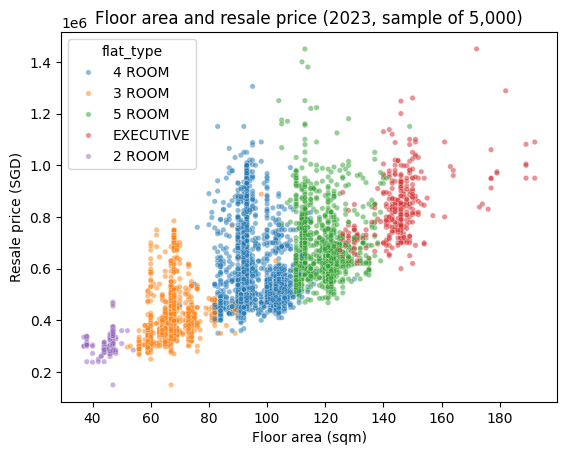

Correlation: 0.68


In [19]:
sample = df_2023.sample(5000, random_state=42)

sns.scatterplot(data=sample, x='floor_area_sqm', y='resale_price', hue='flat_type', alpha=0.5, s=15)
plt.title('Floor area and resale price (2023, sample of 5,000)')
plt.xlabel('Floor area (sqm)')
plt.ylabel('Resale price (SGD)')
plt.show()

print('Correlation:', round(df_2023['floor_area_sqm'].corr(df_2023['resale_price']), 2))


storey_range
01 TO 03     502000.0
04 TO 06     525000.0
07 TO 09     545000.0
10 TO 12     550888.0
13 TO 15     600000.0
16 TO 18     625888.0
19 TO 21     694500.0
22 TO 24     736944.0
25 TO 27     759000.0
28 TO 30     920000.0
31 TO 33     930000.0
34 TO 36     950000.0
37 TO 39     950000.0
40 TO 42    1000000.0
43 TO 45    1230000.0
46 TO 48    1320000.0
49 TO 51    1401969.5
Name: resale_price, dtype: float64


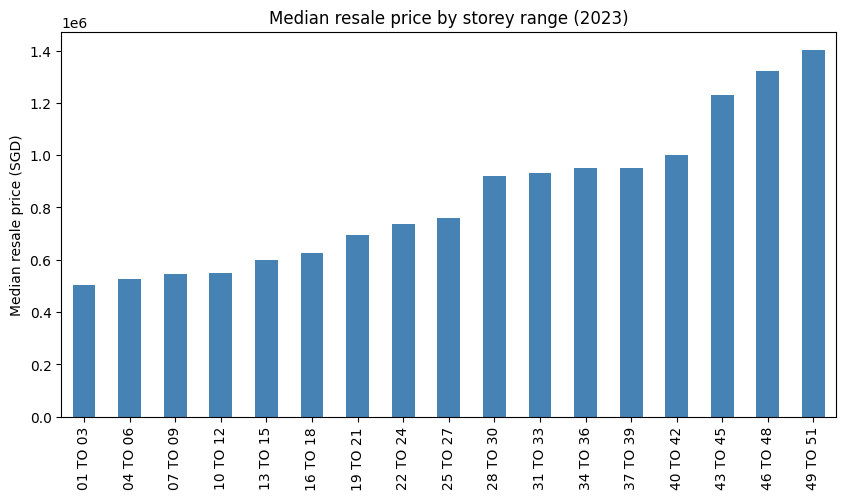

In [20]:
price_storey = df_2023.groupby('storey_range')['resale_price'].median()
print(price_storey)

price_storey.plot(kind='bar', color='steelblue', figsize=(10, 5))
plt.title('Median resale price by storey range (2023)')
plt.ylabel('Median resale price (SGD)')
plt.xlabel('')
plt.show()


flat_model
Model A2             5324.0
New Generation       5408.0
Improved             5472.0
Apartment            5488.0
Simplified           5536.0
Standard             5579.0
Maisonette           5822.0
Model A              6075.0
Premium Apartment    6096.0
DBSS                 9138.0
Name: price_per_sqm, dtype: float64


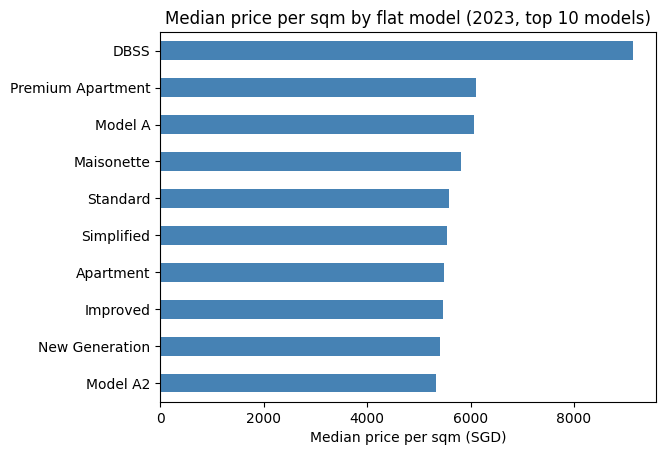

In [21]:
top_models = df_2023['flat_model'].value_counts().head(10).index
price_model = df_2023[df_2023['flat_model'].isin(top_models)].groupby('flat_model')['price_per_sqm'].median().sort_values()
print(price_model.round(0))

price_model.plot(kind='barh', color='steelblue')
plt.title('Median price per sqm by flat model (2023, top 10 models)')
plt.xlabel('Median price per sqm (SGD)')
plt.ylabel('')
plt.show()


**Finding:**
- In 2023 the median price rises with flat size from 241,500 for 1 ROOM to 815,000 for EXECUTIVE.
- Floor area has a strong link with price (correlation 0.68).
- Higher floors cost more. The median is 502,000 on floors 1 to 3 and about 1.4 million on floors 49 to 51.
- DBSS flats have the highest price per sqm (9,138). Most other models are between 5,300 and 6,100.


### 3.2 Objective 2 - Remaining lease (2023)
Price per sqm is used so that flat size does not affect the comparison.


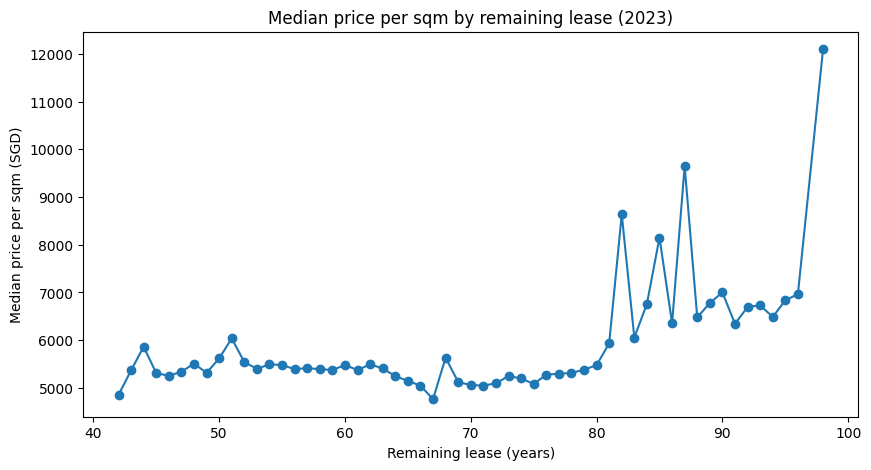

In [22]:
lease_price = df_2023.groupby('remaining_lease_years')['price_per_sqm'].median()

lease_price.plot(kind='line', marker='o', figsize=(10, 5))
plt.title('Median price per sqm by remaining lease (2023)')
plt.xlabel('Remaining lease (years)')
plt.ylabel('Median price per sqm (SGD)')
plt.show()


In [23]:
df_2023_lease = df_2023.copy()
df_2023_lease['lease_band'] = pd.cut(df_2023_lease['remaining_lease_years'],
                                     bins=[0, 60, 70, 80, 90, 99],
                                     labels=['Under 60', '60-70', '70-80', '80-90', '90-99'])

df_2023_lease.groupby('lease_band', observed=True)['price_per_sqm'].agg(['count', 'median'])


,count,median
lease_band,,
Under 60,5779,5447.761194
60-70,5341,5327.868852
70-80,5701,5252.747253
80-90,2268,7014.925373
90-99,6688,6607.142857


### 3.3 Objective 3 - Price and price per sqm by town (2023)

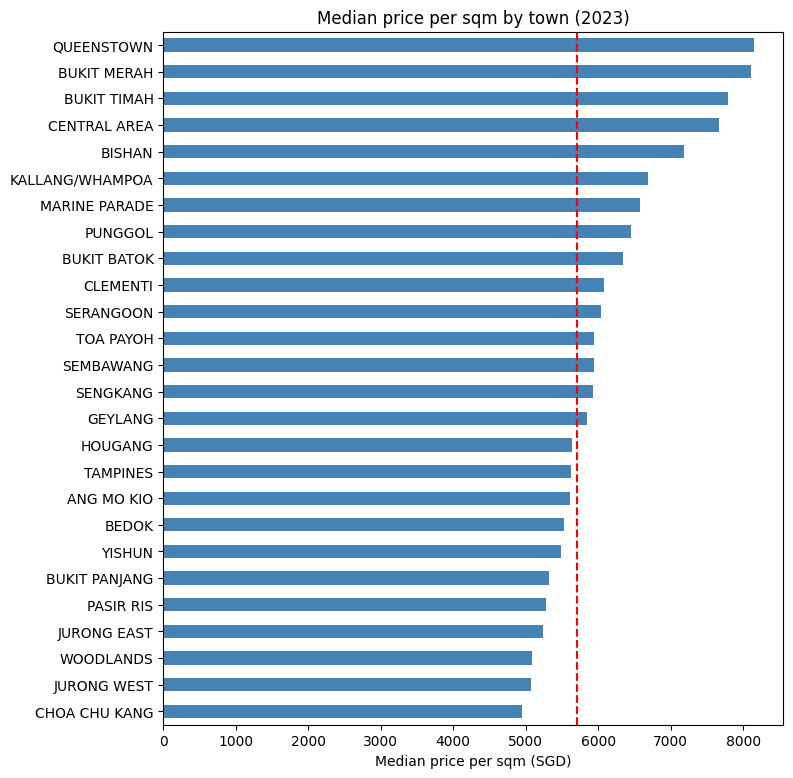

Overall median price per sqm: 5708


In [24]:
town_psm = df_2023.groupby('town')['price_per_sqm'].median().sort_values()

town_psm.plot(kind='barh', color='steelblue', figsize=(8, 9))
plt.axvline(df_2023['price_per_sqm'].median(), color='red', linestyle='--')
plt.title('Median price per sqm by town (2023)')
plt.xlabel('Median price per sqm (SGD)')
plt.ylabel('')
plt.show()

print('Overall median price per sqm:', round(df_2023['price_per_sqm'].median()))


In [25]:
town_price = df_2023.groupby('town')['resale_price'].median().sort_values(ascending=False)
town_price


,resale_price
town,
BUKIT TIMAH,825500.0
BISHAN,750000.0
BUKIT MERAH,726500.0
QUEENSTOWN,700000.0
PASIR RIS,635000.0
KALLANG/WHAMPOA,595000.0
PUNGGOL,590000.0
SERANGOON,584000.0
TAMPINES,580000.0


**Finding:**
- Queenstown, Bukit Merah and Bukit Timah have the highest price per sqm in 2023 (about 7,800 to 8,100).
- Choa Chu Kang, Jurong West and Woodlands are the most affordable (about 5,000).
- The most expensive town costs about 64% more per sqm than the cheapest.


### 3.4 Objective 4 - Price trends and seasonality (2000 to 2023)
2024 is left out because it has only 1 month of data.


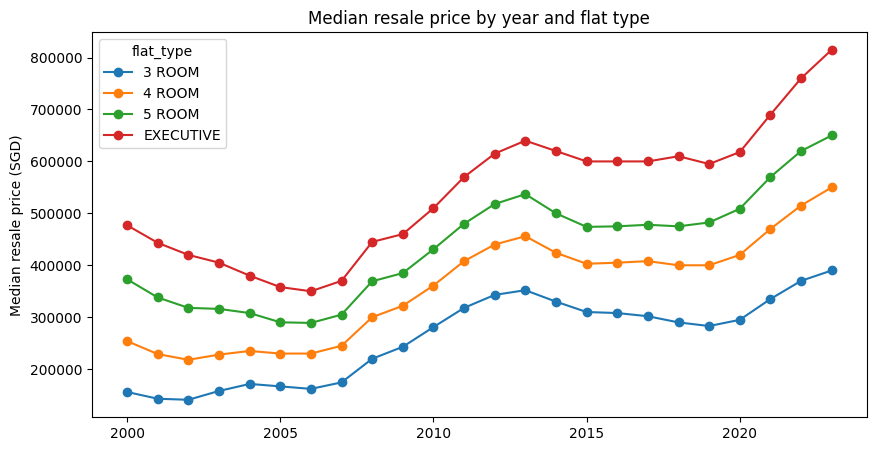

flat_type,3 ROOM,4 ROOM,5 ROOM,EXECUTIVE
year,,,,
2000,156000.0,254000.0,373000.0,477000.0
2013,352000.0,456000.0,537000.0,640000.0
2019,283000.0,400000.0,482500.0,595000.0
2023,390000.0,550000.0,650000.0,815000.0


In [26]:
full_years = df[df['year'] <= 2023]
main_types = ['3 ROOM', '4 ROOM', '5 ROOM', 'EXECUTIVE']

yearly = full_years[full_years['flat_type'].isin(main_types)].groupby(['year', 'flat_type'])['resale_price'].median().unstack()

yearly.plot(kind='line', marker='o', figsize=(10, 5))
plt.title('Median resale price by year and flat type')
plt.ylabel('Median resale price (SGD)')
plt.xlabel('')
plt.show()

yearly.loc[[2000, 2013, 2019, 2023]]


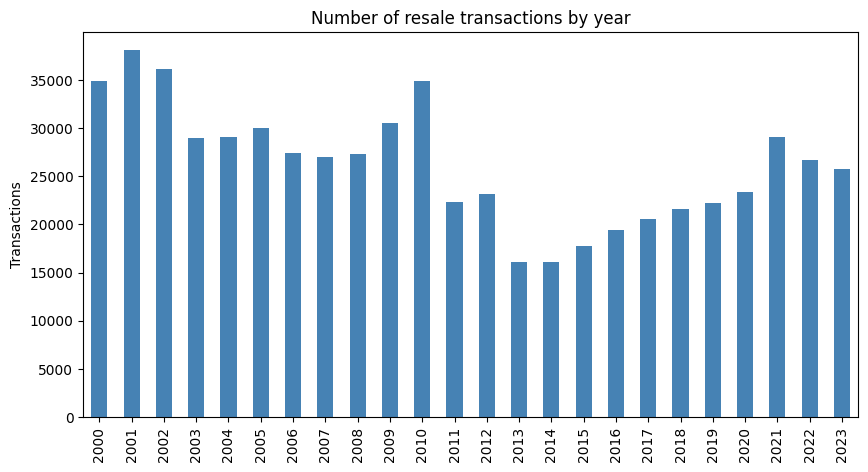

In [27]:
volume = full_years.groupby('year')['resale_price'].count()

volume.plot(kind='bar', color='steelblue', figsize=(10, 5))
plt.title('Number of resale transactions by year')
plt.ylabel('Transactions')
plt.xlabel('')
plt.show()


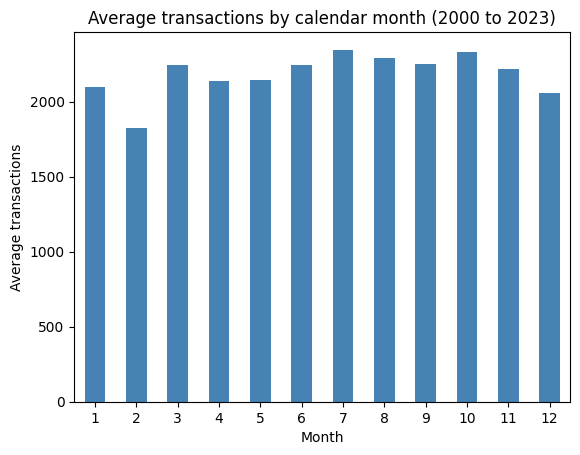

In [28]:
season = full_years.groupby('month_num')['resale_price'].count() / full_years['year'].nunique()

season.plot(kind='bar', color='steelblue')
plt.title('Average transactions by calendar month (2000 to 2023)')
plt.ylabel('Average transactions')
plt.xlabel('Month')
plt.xticks(rotation=0)
plt.show()


**Finding:**
- Median prices of all main flat types more than doubled from 2000 to 2023. The 4 ROOM median rose from 254,000 to 550,000.
- Prices rose to about 2013, fell until 2019 and then rose sharply from 2020.
- Transactions peaked in 2001 at 38,055 and were lowest in 2014 at 16,096.
- February is the quietest month on average. Chinese New Year is a likely reason but the data cannot confirm it.


### 3.5 Objective 5 - Features most linked to resale price (2023)

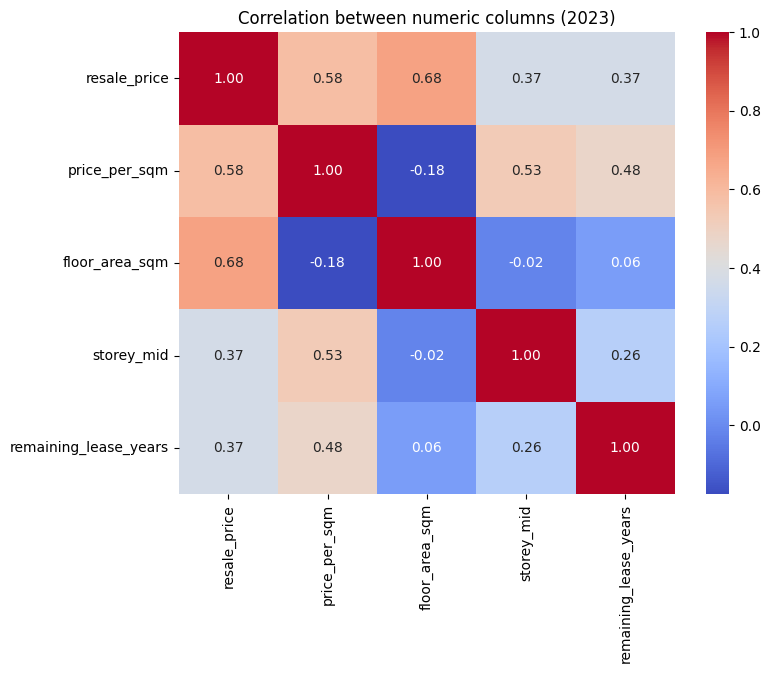

In [29]:
cols = ['resale_price', 'price_per_sqm', 'floor_area_sqm', 'storey_mid', 'remaining_lease_years']

plt.figure(figsize=(8, 6))
sns.heatmap(df_2023[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation between numeric columns (2023)')
plt.show()


**Finding:**
- In 2023 floor area has the strongest link with resale price (0.68). Storey (0.37) and remaining lease (0.37) have moderate links.
- For price per sqm the order changes. Storey (0.53) and remaining lease (0.48) matter most. Floor area is slightly negative (-0.18).
- Bigger flats cost more in total but less per sqm.
- Combined with 3.1 and 3.3: flat size, storey, lease and town all matter. Town and flat model add value that these numbers do not capture.


### 3.6 Summary of findings
1. Flat size and floor area drive the total price. Higher floors add a large premium.
2. Price per sqm is steady for flats with 42 to 80 years of lease left and rises for newer flats.
3. Central towns such as Queenstown and Bukit Merah cost about 64% more per sqm than Choa Chu Kang.
4. Prices more than doubled from 2000 to 2023 with a dip from 2013 to 2019.
5. Floor area links most to total price. Storey and remaining lease link most to price per sqm.
